# Mood sesi (EWMA) dan re-ranking sadar-emosi

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab05_emosi_sesi/02_mood_sesi_dan_reranking.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 5 · Kode 5.5.1 dan 5.5.2

**Tujuan belajar**

- Melacak mood sesi dengan EWMA berbobot keyakinan dan mendeteksi peralihan.
- Menyetel bobot afektif λ pada re-ranking, dan melihat bahwa λ optimum bergantung pada seberapa kuat mood memengaruhi perilaku.
- Mengukur kerusakan akibat koordinat item yang tidak andal, dan peran κ.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> Seluruh sesi dan perilaku pengguna adalah **simulasi** dengan asumsi eksplisit (lihat `sesi`). Ini ilustrasi mekanisme re-ranking, bukan klaim tentang pengguna nyata. Bahwa mood memengaruhi pilihan (parameter `gamma`) adalah **asumsi** yang kita variasikan, bukan fakta.

## 1. Kode dari buku: mood sesi (Kode 5.5.1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def ewma_step(m_prev, v, alpha, kappa=1.0):
    """Satu langkah EWMA; kappa kecil -> item meragukan menggeser mood sedikit."""
    if m_prev is None:
        return np.asarray(v, float)
    a = alpha * kappa
    return a * np.asarray(v, float) + (1 - a) * m_prev

def update_mood(state, v, kappa=1.0, a_main=0.5, a_short=0.6, a_long=0.2, theta=0.35):
    """state: dict berisi 'm', 'short', 'long' (None di awal sesi).
    Mengembalikan state baru, mood teramati, dan tanda peralihan."""
    s = {k: ewma_step(state.get(k), v, a, kappa)
         for k, a in (("m", a_main), ("short", a_short), ("long", a_long))}
    shift = np.linalg.norm(s["short"] - s["long"]) > theta
    mood = s["short"] if shift else s["m"]        # ikuti EWMA pendek saat beralih
    return s, mood, bool(shift)

def target_mood(m, m_goal=None, gamma=0.0):
    """Pers. (5-13): gamma = 0 -> selaras; gamma > 0 -> regulasi ke m_goal."""
    if m_goal is None or gamma == 0:
        return m
    return m + gamma * (np.asarray(m_goal, float) - m)

## 2. Kode dari buku: re-ranking (Kode 5.5.2)

In [2]:
DIAG = 2 * np.sqrt(2)                       # jarak maksimum di [-1, 1]^2

def alignment(V, m):
    """Pers. (5-14): a = 1 - ||v - m|| / (2 sqrt 2); V: (n, 2), m: (2,)."""
    return 1.0 - np.linalg.norm(V - m, axis=1) / DIAG

def rerank(cand_ids, r, V, m_star, K=10, lam=0.3, g_bar_u=None, lam_max=0.6, kappa=None):
    """cand_ids, r: kandidat dan skor Tahap A; V: koordinat VA kandidat."""
    r = np.asarray(r, float)
    r_t = (r - r.min()) / max(r.max() - r.min(), 1e-12)          # Pers. (5-15)
    a = alignment(np.asarray(V, float), np.asarray(m_star, float))
    if kappa is not None:                     # item meragukan -> a ditarik ke netral
        a = kappa * a + (1 - kappa) * 0.5
    if g_bar_u is not None:                   # Pers. (5-17), perluasan konseptual
        lam = lam_max * (1.0 - g_bar_u)
    s = (1 - lam) * r_t + lam * a                                  # Pers. (5-16)
    order = np.argsort(-s)[:K]
    return [cand_ids[j] for j in order], s[order], a[order]

## 3. Simulasi sesi

Asumsi yang dibuat:

- 400 item di empat kuadran valence–arousal.
- Tiap pengguna punya utilitas stabil per item (`u`). Pilihan item pada langkah *t* mengikuti softmax dari `beta · (u + gamma · keselarasan(item, mood_t))`. `gamma` = seberapa kuat mood memengaruhi pilihan.
- Mood sebenarnya konstan pada satu kuadran, lalu (pada sesi "peralihan") pindah ke kuadran lain di tengah sesi.
- Sistem hanya melihat koordinat item yang dikonsumsi, dengan derau `sig_c` (koordinat tidak sempurna).
- Tahap A (mood-buta) memberi skor `u + derau`; re-ranking mengambil 50 kandidat teratas dan memilih 10.

In [3]:
N_ITEM = 400
PUSAT = np.array([[.6, .6], [-.6, .6], [-.6, -.6], [.6, -.6]])

def katalog(seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(PUSAT[rng.integers(0, 4, N_ITEM)] + rng.normal(0, .25, (N_ITEM, 2)), -1, 1)

def sesi(rng, V, T=10, beta=3.0, gamma=1.0, sig_c=0.2, shift=True):
    """Satu sesi: riwayat T item + 1 item target. Mengembalikan utilitas stabil,
    koordinat teramati (berderau) dari riwayat, target, dan mood sebenarnya saat target."""
    u = rng.normal(0, 1, N_ITEM)
    c0 = rng.integers(0, 4); c1 = (c0 + rng.integers(1, 4)) % 4
    moods = [PUSAT[c1] if (shift and t >= T // 2) else PUSAT[c0] for t in range(T + 1)]
    def pilih(m):
        sc = beta * (u + gamma * alignment(V, m))
        p = np.exp(sc - sc.max()); p /= p.sum()
        return rng.choice(N_ITEM, p=p)
    hist = [pilih(m) for m in moods[:T]]
    target = pilih(moods[T])
    V_obs = np.clip(V[hist] + rng.normal(0, sig_c, (T, 2)), -1, 1)
    return u, hist, V_obs, target, moods[T], moods[:T]

V = katalog()
rng = np.random.default_rng(0)
u_, hist_, Vobs_, target_, m_true_, _ = sesi(rng, V)
print("riwayat:", hist_, "| target:", target_, "| mood sebenarnya saat target:", m_true_)

riwayat: [233, 293, 270, 351, 219, 361, 270, 247, 270, 219] | target: 219 | mood sebenarnya saat target: [-0.6 -0.6]


## 4. Eksperimen A: melacak mood dengan EWMA

Pada sesi tanpa peralihan dan dengan peralihan, ukur galat pelacakan di akhir sesi (jarak antara estimasi mood dan mood sebenarnya) untuk beberapa `a_main`.

In [4]:
def estimasi_mood(V_obs, a_main=0.5, theta=0.35, kappas=None):
    st, mood, flags = {}, None, []
    for k, v in enumerate(V_obs):
        st, mood, sh = update_mood(st, v, 1.0 if kappas is None else kappas[k], a_main=a_main, theta=theta)
        flags.append(sh)
    return mood, flags

def galat_pelacakan(a_main, shift, n_sesi=400, sig_c=0.4, seed=0):
    """Deteksi peralihan dimatikan (theta=5) agar efek a_main terlihat murni.
    gamma=3 dan T=14: pilihan cukup mencerminkan mood agar pelacakan bermakna."""
    rng = np.random.default_rng(seed)
    g = []
    for _ in range(n_sesi):
        _, _, V_obs, _, m_true, _ = sesi(rng, V, T=14, gamma=3.0, shift=shift, sig_c=sig_c)
        mood, _ = estimasi_mood(V_obs, a_main=a_main, theta=5.0)
        g.append(np.linalg.norm(mood - m_true))
    return float(np.mean(g))

rows = [{"a_main": a, "tanpa peralihan": galat_pelacakan(a, False), "dengan peralihan": galat_pelacakan(a, True)}
        for a in (0.1, 0.3, 0.5, 0.8)]
lacak = pd.DataFrame(rows).set_index("a_main")
print(lacak.round(3))
assert lacak.loc[0.1, "tanpa peralihan"] < lacak.loc[0.8, "tanpa peralihan"]      # stabil: EWMA lambat unggul
assert lacak.loc[0.1, "dengan peralihan"] > lacak.loc[0.3, "dengan peralihan"]    # peralihan: EWMA lambat tertinggal

        tanpa peralihan  dengan peralihan
a_main                                   
0.1               0.304             0.695
0.3               0.328             0.376
0.5               0.390             0.408
0.8               0.496             0.523


**Interpretasi (simulasi).** Ada pertukaran klasik. `a_main` kecil meredam derau koordinat, tetapi lambat mengikuti peralihan. `a_main` besar cepat mengikuti peralihan, tetapi ikut terbawa derau. Pada sesi stabil, `a_main` kecil paling akurat; pada sesi dengan peralihan, `a_main = 0,1` justru jauh lebih buruk daripada 0,3 karena terlambat mengikuti. Deteksi peralihan (`theta`) di buku ada untuk menutup kelemahan itu: saat EWMA pendek dan panjang berjauhan, sistem mengikuti EWMA pendek.

In [5]:
def galat_dengan_deteksi(theta, shift, n_sesi=400, sig_c=0.4, seed=0):
    rng = np.random.default_rng(seed)
    g = []
    for _ in range(n_sesi):
        _, _, V_obs, _, m_true, _ = sesi(rng, V, T=14, gamma=3.0, shift=shift, sig_c=sig_c)
        mood, _ = estimasi_mood(V_obs, a_main=0.1, theta=theta)       # a_main lambat, bergantung pada deteksi
        g.append(np.linalg.norm(mood - m_true))
    return float(np.mean(g))

rows = [{"theta": th, "tanpa peralihan": galat_dengan_deteksi(th, False), "dengan peralihan": galat_dengan_deteksi(th, True)}
        for th in (0.15, 0.35, 0.6, 5.0)]
deteksi = pd.DataFrame(rows).set_index("theta")
print(deteksi.round(3))
assert deteksi.loc[0.35, "dengan peralihan"] < deteksi.loc[5.0, "dengan peralihan"]    # deteksi membantu saat ada peralihan
assert deteksi.loc[0.35, "tanpa peralihan"] > deteksi.loc[5.0, "tanpa peralihan"]      # tetapi menambah alarm palsu saat stabil

       tanpa peralihan  dengan peralihan
theta                                   
0.15             0.413             0.465
0.35             0.361             0.569
0.60             0.315             0.686
5.00             0.304             0.695


**Interpretasi.** `theta = 5` setara dengan mematikan deteksi (jarak maksimum hanya 2,83). Pada sesi dengan peralihan, `theta` kecil menurunkan galat jauh dibanding EWMA lambat saja. Harganya terlihat pada sesi tanpa peralihan: `theta` kecil memicu alarm palsu karena derau, sehingga galat naik. Nilai `theta` adalah kompromi antara kepekaan dan alarm palsu.

## 5. Eksperimen B: bobot keyakinan κ pada EWMA

Setengah item punya koordinat yang buruk (derau 1,0, κ = 0,2) dan setengahnya baik (derau 0,15, κ = 0,9). Bandingkan EWMA tanpa κ dengan EWMA berbobot κ.

In [6]:
def galat_kappa(pakai_kappa, n_sesi=500, seed=0):
    """gamma=3, T=14 seperti di atas."""
    rng = np.random.default_rng(seed)
    g = []
    for _ in range(n_sesi):
        u, hist, _, _, m_true, _ = sesi(rng, V, T=14, gamma=3.0, shift=False)
        buruk = rng.random(len(hist)) < 0.5
        sig = np.where(buruk, 1.0, 0.15)[:, None]
        V_obs = np.clip(V[hist] + rng.normal(0, 1, (len(hist), 2)) * sig, -1, 1)
        kap = np.where(buruk, 0.2, 0.9) if pakai_kappa else None
        mood, _ = estimasi_mood(V_obs, a_main=0.5, kappas=kap)
        g.append(np.linalg.norm(mood - m_true))
    return float(np.mean(g))

e0, e1 = galat_kappa(False), galat_kappa(True)
print(f"galat pelacakan tanpa κ: {e0:.3f} | dengan κ: {e1:.3f}")
assert e1 < e0

galat pelacakan tanpa κ: 0.515 | dengan κ: 0.347


**Interpretasi.** Bila κ memang informatif (item ber-derau tinggi diberi κ rendah), EWMA berbobot κ melacak mood lebih baik. Jika κ tidak berkaitan dengan kualitas koordinat, manfaat ini hilang. Sama seperti gerbang konfidens di Bab 3, κ hanya berguna jika benar-benar membawa informasi.

## 6. Eksperimen C: berapa bobot λ yang pantas untuk re-ranking?

Ukuran: *hit rate@10* dari item target berikutnya, pada 800 sesi per sel. Variasikan λ dan kekuatan pengaruh mood terhadap perilaku (`gamma`). `gamma = 0` berarti mood tidak memengaruhi pilihan sama sekali.

        gamma=0.0  gamma=1.0  gamma=2.0
lambda                                 
0.0         0.521      0.484      0.450
0.2         0.538      0.504      0.484
0.4         0.538      0.509      0.524
0.6         0.511      0.488      0.552
0.8         0.430      0.419      0.495


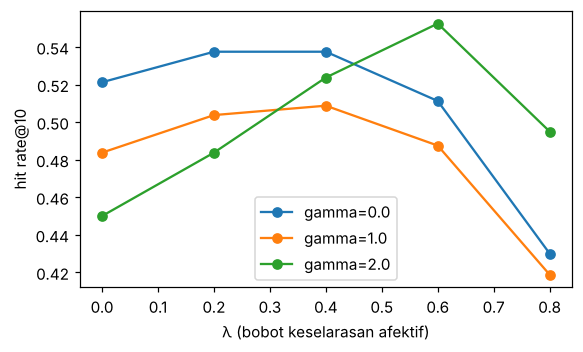

In [7]:
def hit_rate(lam, gamma, sig_c=0.2, n_sesi=800, seed=1, kappa_fn=None):
    rng = np.random.default_rng(seed)
    hit = 0
    for _ in range(n_sesi):
        u, hist, V_obs, target, m_true, _ = sesi(rng, V, gamma=gamma, sig_c=sig_c)
        r = u + rng.normal(0, 0.7, N_ITEM)                  # Tahap A, buta mood
        cand = np.argsort(-r)[:50]
        mood, _ = estimasi_mood(V_obs)
        top, _, _ = rerank(cand, r[cand], V[cand], mood, K=10, lam=lam)
        hit += target in top
    return hit / n_sesi

lams = (0.0, 0.2, 0.4, 0.6, 0.8)
tab_lam = pd.DataFrame({f"gamma={g}": [hit_rate(l, g) for l in lams] for g in (0.0, 1.0, 2.0)}, index=lams)
tab_lam.index.name = "lambda"
print(tab_lam.round(3))

fig, ax = plt.subplots(figsize=(5.4, 3.3))
tab_lam.plot(ax=ax, marker="o")
ax.set(xlabel="λ (bobot keselarasan afektif)", ylabel="hit rate@10")
fig.tight_layout()

# klaim yang diuji
assert tab_lam["gamma=0.0"].iloc[-1] < tab_lam["gamma=0.0"].iloc[0]          # mood tidak relevan: re-ranking merusak
assert tab_lam["gamma=1.0"].max() > tab_lam["gamma=1.0"].iloc[0] + 0.01       # mood relevan: ada λ yang membantu
assert tab_lam["gamma=1.0"].idxmax() not in (lams[0], lams[-1])               # λ optimum bukan di ekstrem

**Interpretasi (simulasi dengan asumsi di atas).**

1. Bila mood **tidak** memengaruhi perilaku (`gamma = 0`), re-ranking tidak memberi manfaat yang berarti (selisih kecil pada λ rendah masih dalam rentang derau simulasi), dan λ besar menurunkan hit rate karena menggeser rekomendasi menjauhi preferensi stabil. Re-ranking afektif bukan perbaikan universal.
2. Bila mood berpengaruh sedang (`gamma = 1`), ada λ menengah yang memberi kenaikan nyata, dan λ yang terlalu besar mengabaikan relevansi sehingga hasil menurun lagi. Bentuk U terbalik ini yang menjadi alasan λ harus disetel pada validasi.
3. Bila mood sangat berpengaruh (`gamma = 2`), λ optimum bergeser ke nilai yang lebih besar.

Karena `gamma` pada data nyata tidak diketahui, λ **tidak boleh** ditetapkan dari intuisi. Perhatikan juga bahwa `gamma` di sini adalah asumsi simulasi: apakah pengguna nyata berperilaku demikian adalah pertanyaan empiris.

## 7. Eksperimen D: koordinat item yang tidak andal

Pada Eksperimen C koordinat item (`V`) dipakai langsung. Di sini, sebagian item mendapat koordinat yang salah (acak) dan kita bandingkan re-ranking tanpa κ dengan re-ranking yang menarik keselarasan item meragukan ke netral (`kappa`).

In [8]:
def hit_rate_koordinat_salah(pakai_kappa, lam=0.4, gamma=1.0, frac_salah=0.4, n_sesi=800, seed=2):
    rng_k = np.random.default_rng(99)
    salah = rng_k.random(N_ITEM) < frac_salah                       # item dengan koordinat tidak andal
    V_dipercaya = np.where(salah[:, None], rng_k.uniform(-1, 1, (N_ITEM, 2)), V)   # koordinat yang diketahui sistem
    kappa_item = np.where(salah, 0.1, 0.9)
    rng = np.random.default_rng(seed)
    hit = 0
    for _ in range(n_sesi):
        u, hist, V_obs, target, m_true, _ = sesi(rng, V, gamma=gamma)
        r = u + rng.normal(0, 0.7, N_ITEM)
        cand = np.argsort(-r)[:50]
        mood, _ = estimasi_mood(V_obs)
        top, _, _ = rerank(cand, r[cand], V_dipercaya[cand], mood, K=10, lam=lam,
                           kappa=kappa_item[cand] if pakai_kappa else None)
        hit += target in top
    return hit / n_sesi

dasar = hit_rate(0.0, 2.0)
rows = [{"porsi koordinat salah": f,
         "tanpa re-ranking": dasar,
         "re-rank tanpa κ": hit_rate_koordinat_salah(False, lam=0.6, gamma=2.0, frac_salah=f),
         "re-rank dengan κ": hit_rate_koordinat_salah(True, lam=0.6, gamma=2.0, frac_salah=f)}
        for f in (0.0, 0.4, 0.7, 0.9)]
tab_salah = pd.DataFrame(rows).set_index("porsi koordinat salah")
print(tab_salah.round(3))
assert tab_salah.loc[0.9, "re-rank dengan κ"] > tab_salah.loc[0.9, "re-rank tanpa κ"] + 0.02
assert tab_salah.loc[0.9, "re-rank tanpa κ"] < tab_salah.loc[0.9, "tanpa re-ranking"] + 0.01   # tanpa κ: manfaat lenyap

                       tanpa re-ranking  re-rank tanpa κ  re-rank dengan κ
porsi koordinat salah                                                     
0.0                                0.45            0.584             0.585
0.4                                0.45            0.518             0.530
0.7                                0.45            0.476             0.506
0.9                                0.45            0.442             0.501


**Interpretasi (simulasi, gamma = 2, λ = 0,6).** Seiring bertambahnya porsi koordinat yang salah, manfaat re-ranking tanpa κ menyusut dan pada porsi 0,9 tidak lebih baik daripada tanpa re-ranking. Dengan κ, keselarasan item yang diragukan ditarik ke netral sehingga sebagian besar manfaat bertahan. Pada porsi kecil, selisih keduanya berada dalam rentang derau simulasi (±0,02), jadi jangan menafsirkan perbedaan kecil itu. Kualitas koordinat tetap hulu dari semuanya.

## Pertanyaan refleksi

1. Mengapa `rerank` menormalkan skor Tahap A ke [0, 1] sebelum dicampur dengan keselarasan?
2. Pada Eksperimen C, apa yang terjadi bila Tahap A bukan `u + derau 0,7`, tetapi `u + derau 0,1` (Tahap A jauh lebih akurat)? Prediksikan dulu, lalu jalankan.
3. `target_mood` dengan `gamma > 0` mengarahkan pengguna ke mood tujuan. Kapan ini pantas dipakai, dan apa risiko etisnya (manipulasi emosi)?